<a href="https://colab.research.google.com/github/Crisstudy/Coleta-Limpeza-e-Tratamento-de-Dados/blob/main/Atividade_pratica_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    mean_squared_error,
    r2_score,
    confusion_matrix,
    classification_report
)
import matplotlib.pyplot as plt

In [13]:
np.random.seed(42)
meses = np.arange(1, 25)
vendas = np.random.normal(200, 50, 24)
eventos = np.random.choice([0, 1], size=24)
df_vendas = pd.DataFrame({
    'Meses': meses,
    'Vendas': vendas,
    'Eventos': eventos
})

In [14]:
X_vendas = df_vendas[['Meses', 'Eventos']]
Y_vendas = df_vendas['Vendas']
X_train_vendas, X_test_vendas, Y_train_vendas, Y_test_vendas = train_test_split(X_vendas, Y_vendas, test_size= 0.3, random_state=42)
df_vendas.head()

,Meses,Vendas,Eventos
0,1,224.835708,1
1,2,193.086785,0
2,3,232.384427,0
3,4,276.151493,0
4,5,188.292331,0


Erro Médio Quadrático: 3048.9676839648832
Coeficiente de Determinação (R²):-1.103641785560324


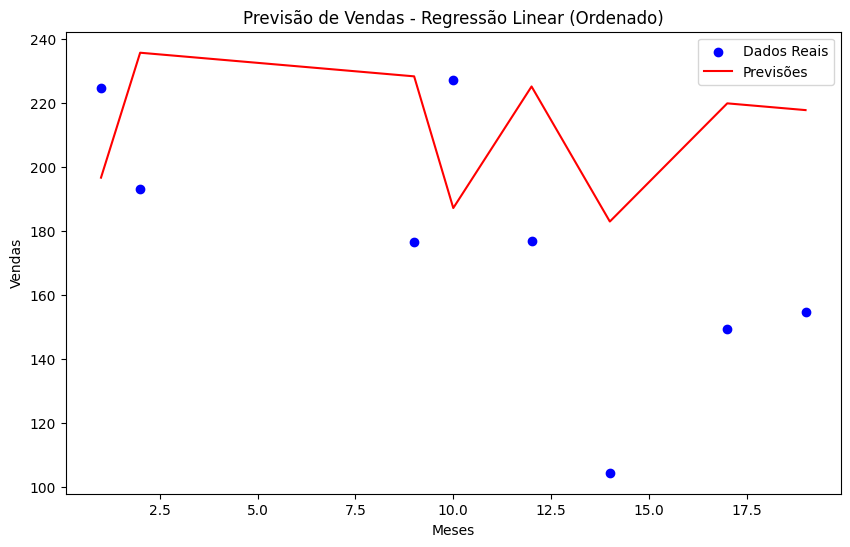

In [15]:
model_vendas = LinearRegression()
model_vendas.fit(X_train_vendas, Y_train_vendas)
Y_pred_vendas = model_vendas.predict(X_test_vendas)
mse_vendas = mean_squared_error(Y_test_vendas, Y_pred_vendas)
r2_vendas = r2_score(Y_test_vendas, Y_pred_vendas)
print(f'Erro Médio Quadrático: {mse_vendas}')
print(f'Coeficiente de Determinação (R²):{r2_vendas}')
ordenado = X_test_vendas['Meses'].argsort()

plt.figure(figsize=(10,6))
plt.scatter(X_test_vendas['Meses'], Y_test_vendas, color='blue', label='Dados Reais')
plt.plot(X_test_vendas['Meses'].iloc[ordenado], Y_pred_vendas[ordenado], color='red', label='Previsões')
plt.title('Previsão de Vendas - Regressão Linear (Ordenado)')
plt.xlabel('Meses')
plt.ylabel('Vendas')
plt.legend()
plt.show()

In [16]:
np.random.seed(42)

valores = np.random.normal(1000, 200, 1000)
locais = np.random.choice(['Local_A', 'Local_B', 'Local_C'], size=1000)
fraudes = np.random.choice([0, 1], size=1000)  # 0 = Não fraude, 1 = Fraude
df_fraudes = pd.DataFrame({
  'Valores': valores,
  'Locais': locais,
  'Fraude': fraudes
})

In [18]:
df_fraudes = pd.get_dummies(df_fraudes, columns=['Locais'])
X_fraudes = df_fraudes.drop('Fraude', axis=1)
y_fraudes = df_fraudes['Fraude']
X_train_fraudes, X_test_fraudes, y_train_fraudes, y_test_fraudes = train_test_split(X_fraudes, y_fraudes, test_size=0.3, random_state=42)

In [19]:
model_fraudes = LogisticRegression()
model_fraudes.fit(X_train_fraudes, y_train_fraudes)
y_pred_fraudes = model_fraudes.predict(X_test_fraudes)
accuracy_fraudes = accuracy_score(y_test_fraudes, y_pred_fraudes)
confusion = confusion_matrix(y_test_fraudes, y_pred_fraudes)
report = classification_report(y_test_fraudes, y_pred_fraudes)
print(f'Acurácia do modelo: {accuracy_fraudes}')
print('Matriz de Confusão:')
print(confusion)
print('Relatório de Classificação:')
print(report)


Acurácia do modelo: 0.49666666666666665
Matriz de Confusão:
[[120  23]
 [128  29]]
Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.48      0.84      0.61       143
           1       0.56      0.18      0.28       157

    accuracy                           0.50       300
   macro avg       0.52      0.51      0.45       300
weighted avg       0.52      0.50      0.44       300

